# Political group or national party

Roadmap step 3, part 2. Members are elected on national party lists but vote in European political groups. When the two pull in different directions, which do members follow?

**Definitions** (shared code in `explanation.py`):

- The **group line** is the group's most common position among For, Against and Abstention, with the member included (see notebook 01).
- The **national party line** is the position that all the member's other active national party colleagues took on the roll call, when there are at least two of them. If the colleagues disagree among themselves, there is no national party line. This is a revealed line from votes, not a recorded whip instruction.
- A **conflict** is a roll call where both lines exist and differ.

Members whose national party has fewer than three active members on a roll call have no national party line, so this covers larger national delegations only. Contested roll calls as before (2.5%). Non-attached members have no group line and are left out.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from explanation import NON_ATTACHED, POSITIONS, defection_rows, follows, independent_party_ids
from howtheyvote import load, load_rollcalls, load_votes

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # categorical slots 1 to 3
NEUTRAL = "#52514e"
MUTED = "#c9c8c1"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})

TERMS = [9, 10]
# Display order from the polarization clustering maps; non-attached members last.
GROUP_ORDER = ["GREEN_EFA", "GUE_NGL", "SD", "RENEW", "EPP", "ECR", "ID", "PFE", "ESN", "NI"]
LABELS = {"GUE_NGL": "The Left", "GREEN_EFA": "Greens/EFA", "SD": "S&D", "RENEW": "Renew", "EPP": "EPP",
          "ECR": "ECR", "ID": "ID", "PFE": "PfE", "ESN": "ESN", "NI": "Non-attached"}
TERM_10_START = pd.Timestamp("2024-07-16")


def half_label(value):
    return f"{int(value)} {'H2' if value % 1 else 'H1'}"


def ordered(index):
    return [g for g in GROUP_ORDER if g in set(index)]


rollcalls = load_rollcalls()
rollcalls = rollcalls[~rollcalls["is_secret"]].set_index("vote_id")
rollcalls["half"] = rollcalls["date"].dt.year + (rollcalls["date"].dt.month > 6) * 0.5
# Responsible committee as the topic of a roll call. 1,196 roll calls have two or three (joint committees).
committees = load("subjects").query("scheme == 'committee'")
joint = committees.groupby("vote_id")["code"].nunique() > 1
first = committees.drop_duplicates("vote_id").set_index("vote_id")
rollcalls["committee"] = first["code"].where(~joint.reindex(first.index), "JOINT")
COMMITTEE_LABELS = dict(zip(committees["code"], committees["label"])) | {"JOINT": "Joint committees"}

# Members filed under the export's "Independent" entries have no national party.
independents = independent_party_ids(load("national_parties"))
frames = []
for term in TERMS:
    frames.append(defection_rows(load_votes(term), no_party_ids=independents))
rows = pd.concat(frames, ignore_index=True)
del frames
rows = rows.join(rollcalls[["half", "minority_share", "minority_share_with_abstention", "vote_part",
                            "committee"]], on="vote_id")
contested = rows[rows["minority_share"] >= 0.025]
print(f"{len(rows):,} active positions; {len(contested):,} on contested roll calls")

grouped = contested[contested["group_code"] != NON_ATTACHED].copy()
both = grouped.dropna(subset=["conflict"])
print("Share of group members' positions with a national party line:",
      grouped.groupby("term")["party_line"].apply(lambda s: (s >= 0).mean()).round(3).to_dict())
print("Share of positions against united national colleagues, all positions with a national party line:",
      grouped.groupby("term")["defected_party"].mean().round(4).to_dict())
print("The same, on positions where the national party line matches the group line:",
      both[both["conflict"] == 0].groupby("term")["defected_party"].mean().round(4).to_dict())

16,616,129 active positions; 15,624,395 on contested roll calls


Share of group members' positions with a national party line: {np.int8(9): 0.648, np.int8(10): 0.654}


Share of positions against united national colleagues, all positions with a national party line: {np.int8(9): 0.008500000461935997, np.int8(10): 0.009200000204145908}


The same, on positions where the national party line matches the group line: {np.int8(9): 0.0067, np.int8(10): 0.007}


## How often the two lines conflict, and whom members follow

In [2]:
conflicts = both[both["conflict"] == 1].copy()
conflicts["follows"] = follows(conflicts)
table = both.groupby(["term", "group_code"]).agg(positions=("conflict", "size"), conflict_rate=("conflict", "mean"))
shares = conflicts.groupby(["term", "group_code"])["follows"].value_counts(normalize=True).unstack(fill_value=0)
table = table.join(shares)
overall = both.groupby("term").agg(positions=("conflict", "size"), conflict_rate=("conflict", "mean")).join(
    conflicts.groupby("term")["follows"].value_counts(normalize=True).unstack(fill_value=0))
table = pd.concat([table, overall.assign(group_code="all groups").set_index("group_code", append=True)])
table = table.reindex(pd.MultiIndex.from_product([TERMS, GROUP_ORDER[:-1] + ["all groups"]])).dropna(how="all")
display(table.rename(index=LABELS, level=1).round(3))

positions  conflict_rate  group  national party  neither
9  Greens/EFA   738941.0          0.008  0.049           0.939    0.012
   The Left     238152.0          0.052  0.051           0.932    0.017
   S&D         1687332.0          0.027  0.053           0.937    0.011
   Renew        862248.0          0.070  0.032           0.959    0.009
   EPP         2010395.0          0.036  0.059           0.926    0.015
   ECR          738393.0          0.130  0.024           0.968    0.008
   ID           925993.0          0.210  0.004           0.993    0.003
   all groups  7201454.0          0.068  0.026           0.967    0.008
10 Greens/EFA   152497.0          0.018  0.061           0.927    0.012
   The Left     122804.0          0.065  0.023           0.960    0.017
   S&D          540589.0          0.024  0.055           0.931    0.014
   Renew        186505.0          0.059  0.082           0.912    0.006
   EPP          679105.0          0.035  0.055           0.921    0.024
   ECR          287093.0          0.089  0.029           0.962    0.009
   PfE          391908.0          0.145  0.008           0.987    0.004
   ESN           88617.0          0.018  0.156           0.799    0.045
   all groups  2449118.0          0.058  0.033           0.956    0.011

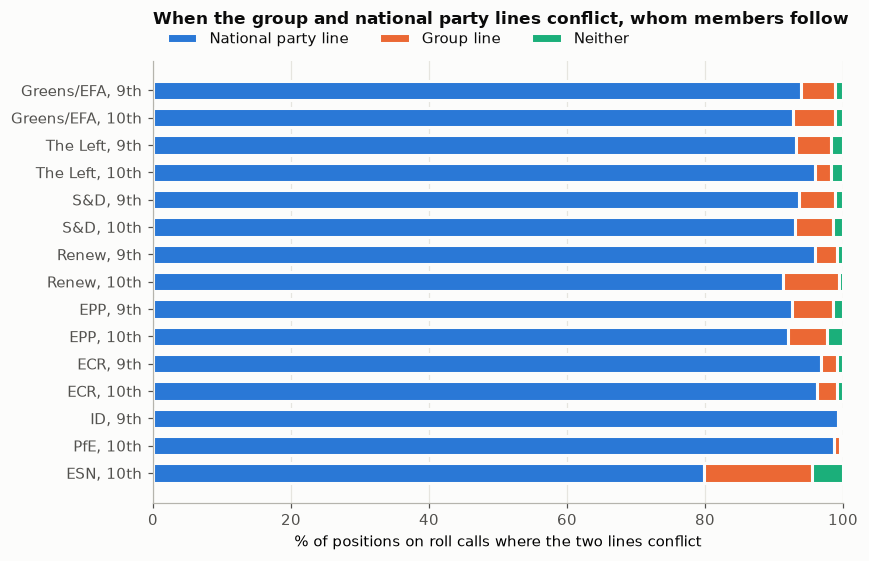

In [3]:
shares = conflicts.groupby(["group_code", "term"])["follows"].value_counts(normalize=True).unstack(fill_value=0)
shares = shares.reindex(pd.MultiIndex.from_tuples([(g, t) for g in ordered(conflicts["group_code"]) for t in TERMS
                                                    if (g, t) in shares.index]))
labels = [f"{LABELS[g]}, {t}th" for g, t in shares.index]
fig, axis = plt.subplots(figsize=(8, 5.2))
positions = np.arange(len(shares))[::-1]
left = np.zeros(len(shares))
for column, color, name in zip(["national party", "group", "neither"], SERIES,
                               ["National party line", "Group line", "Neither"]):
    axis.barh(positions, shares[column] * 100, left=left, color=color, label=name, height=0.7,
              edgecolor="#fcfcfb", linewidth=2)
    left += shares[column].to_numpy() * 100
axis.set_yticks(positions, labels)
axis.set_xlim(0, 100)
axis.set_xlabel("% of positions on roll calls where the two lines conflict")
axis.set_title("When the group and national party lines conflict, whom members follow", pad=24)
axis.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
axis.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

**What this shows**

- **About 65% of group members' positions have a national party line.** The rest belong to members with fewer than two active colleagues, or whose colleagues split.
- **Where both lines exist, they conflict on 6.8% of positions in the 9th term and 5.8% in the 10th.** Conflicts are rare in Greens/EFA (0.8% and 1.8%), S&D (2.7% and 2.4%) and ESN (1.8%). They are common in ID (21%), PfE (14.5%) and ECR (13.0% and 8.9%).
- **When the lines conflict, members vote with their national party 96.7% and 95.6% of the time.** They take the group line on 2.6% and 3.3%.
  - Every group follows the national party on 91% or more of its conflicts, except ESN (80%) in the 10th term.
  - ID (99.3%) and PfE (98.7%) follow it almost always.

For comparison, members vote against united national colleagues on 0.85% and 0.92% of all positions with a national party line, and 0.67% and 0.70% when the two lines agree. On conflicts that rises only to 3.3% and 4.4%, while agreement with the group line collapses.

## Where group defections come from

Each defection from the group line falls into one of three cases:

- **with the national party:** the member's national party colleagues were united against the group line, and the member voted with them;
- **against both:** colleagues were united behind the group line or united on a third position, and the member voted differently from them too;
- **no national party line:** the member had fewer than two active colleagues, or the colleagues were divided.

In [4]:
defections = grouped[grouped["defected_group"] == 1].copy()
defections["source"] = np.select(
    [defections["party_line"] < 0, defections["position_code"] == defections["party_line"]],
    ["no national party line", "with the national party"], "against both")
sources = defections.groupby(["term", "group_code"])["source"].value_counts(normalize=True).unstack(fill_value=0)
overall = defections.groupby("term")["source"].value_counts(normalize=True).unstack(fill_value=0)
sources = pd.concat([sources, overall.assign(group_code="all groups").set_index("group_code", append=True)])
sources = sources.reindex(pd.MultiIndex.from_product([TERMS, GROUP_ORDER[:-1] + ["all groups"]])).dropna(how="all")
display(sources.rename(index=LABELS, level=1).round(3))
with_line = defections[defections["party_line"] >= 0]
print("Among defections where a national party line exists, share with the national party:",
      with_line.groupby("term")["source"].apply(lambda s: s.eq("with the national party").mean()).round(3).to_dict())

source         against both  no national party line  with the national party
9  Greens/EFA         0.107                   0.692                    0.201
   The Left           0.035                   0.778                    0.187
   S&D                0.093                   0.562                    0.345
   Renew              0.048                   0.516                    0.437
   EPP                0.082                   0.613                    0.305
   ECR                0.028                   0.350                    0.623
   ID                 0.015                   0.259                    0.726
   all groups         0.050                   0.470                    0.480
10 Greens/EFA         0.060                   0.742                    0.198
   The Left           0.039                   0.574                    0.387
   S&D                0.103                   0.547                    0.349
   Renew              0.038                   0.549                    0.413
   EPP                0.093                   0.619                    0.288
   ECR                0.035                   0.523                    0.442
   PfE                0.018                   0.198                    0.784
   ESN                0.091                   0.817                    0.092
   all groups         0.057                   0.502                    0.441

Among defections where a national party line exists, share with the national party: {np.int8(9): 0.906, np.int8(10): 0.885}


**What this shows**

- **Defection from the group is mostly collective.** About 48% (9th term) and 44% (10th) of all group defections are members voting with national colleagues who were united against the group line.
  - Another 5% to 6% go against both the group and united colleagues.
  - The rest (47% and 50%) are by members without a national party line: no or one colleague, or divided colleagues.
- **Where a national party line exists, 91% and 89% of defections are with it.**
- **On the right, defection is mostly national parties breaking away together:** 62% (ECR, 9th term), 73% (ID) and 78% (PfE) of their defections are with the national party.
- **In Greens/EFA and The Left, most defections are by members without a national party line** (57% to 78%), so they are more individual or by small delegations.

## National party size

The number of the member's other active national party colleagues on the roll call.

In [5]:
# Counted over all active members of the national party on the roll call, not only those with both lines.
colleagues = rows.groupby(["vote_id", "national_party_id"])["member_id"].transform("size") - 1
both["colleagues"] = pd.cut(colleagues.reindex(both.index), [1, 2, 4, 9, 200],
                            labels=["2", "3 to 4", "5 to 9", "10 or more"])
conflicts = conflicts.join(both["colleagues"])
size_table = both.groupby(["term", "colleagues"], observed=True).agg(
    positions=("conflict", "size"), conflict_rate=("conflict", "mean"))
size_table = size_table.join(conflicts.groupby(["term", "colleagues"], observed=True)["follows"].value_counts(
    normalize=True).unstack(fill_value=0))
display(size_table.round(3))

positions  conflict_rate  group  national party  neither
term colleagues                                                          
9    2              899909          0.129  0.029           0.961    0.010
     3 to 4        1637402          0.074  0.033           0.956    0.011
     5 to 9        1706425          0.049  0.039           0.952    0.009
     10 or more    2957718          0.057  0.012           0.985    0.003
10   2              364254          0.085  0.074           0.908    0.018
     3 to 4         464127          0.077  0.038           0.946    0.015
     5 to 9         605031          0.081  0.014           0.981    0.006
     10 or more    1015706          0.026  0.015           0.979    0.006

**Smaller delegations conflict with their group more often:** 12.9% of positions for members with two colleagues, against 5.7% for delegations of ten or more (9th term). In the 10th term the largest delegations conflict least (2.6%). Whatever the size, members follow the national party on about 91% or more of conflicts, and on 98% in the largest delegations. Large national parties often make up much of their group's majority, so their line and the group line coincide more often.

## By kind of roll call

In [6]:
part_table = both.groupby(["term", "vote_part"]).agg(positions=("conflict", "size"), conflict_rate=("conflict", "mean"))
part_table = part_table.join(conflicts.groupby(["term", "vote_part"])["follows"].value_counts(normalize=True).unstack(fill_value=0))
display(part_table.round(3))

positions  conflict_rate  group  national party  neither
term vote_part                                                           
9    amendment     4247161          0.064  0.027           0.966    0.007
     final          565035          0.075  0.025           0.967    0.008
     other          178922          0.056  0.019           0.975    0.005
     procedural      53507          0.043  0.058           0.928    0.014
     text part     2156829          0.075  0.023           0.967    0.010
10   amendment     1590040          0.053  0.036           0.955    0.009
     final          242836          0.073  0.024           0.967    0.010
     other           35768          0.061  0.030           0.960    0.011
     procedural      28618          0.036  0.043           0.944    0.014
     text part      551856          0.068  0.032           0.953    0.014

**Conflicts are a little more common on final votes and parts of a text** (6.8% to 7.5%) than on amendments (5.3% to 6.4%). The share following the national party is above 92% on every kind of roll call.

## Which national parties conflict most with their group

National parties with at least 200 positions with both lines in the term, ranked by conflict rate. Names are the export's labels.

In [7]:
parties = load("national_parties").set_index("national_party_id")
by_party = both.groupby(["term", "national_party_id"]).agg(
    positions=("conflict", "size"), conflict_rate=("conflict", "mean"),
    group=("group_code", lambda s: s.mode()[0]), country=("country_code", "first"),
    members=("member_id", "nunique"))
by_party = by_party[by_party["positions"] >= 200]
by_party["party"] = parties["label"].reindex(by_party.index.get_level_values(1)).to_numpy()
by_party["group"] = by_party["group"].map(LABELS)
for term in TERMS:
    data = by_party.loc[term].sort_values("conflict_rate", ascending=False)
    print(f"{term}th term: {len(data)} national parties; conflict rate median {data['conflict_rate'].median():.3f}")
    display(data.head(12)[["party", "country", "group", "members", "positions", "conflict_rate"]].round(3))

9th term: 81 national parties; conflict rate median 0.037


,party,country,group,members,positions,conflict_rate
national_party_id,,,,,,
5533,Forum voor Democratie,NLD,ECR,3,14876,0.451
6260,JA21,NLD,ECR,4,24883,0.442
5233,Conservative Party,GBR,ECR,4,1476,0.388
5393,Sverigedemokraterna,SWE,ECR,4,45279,0.380
5173,Nieuw-Vlaamse Alliantie,BEL,ECR,3,44641,0.358
5164,Freiheitliche Partei Österreichs,AUT,ID,3,49892,0.313
5170,Vlaams Belang,BEL,ID,3,46011,0.301
5369,Alternative für Deutschland,DEU,ID,11,155765,0.267
5494,Rassemblement national,FRA,ID,26,324022,0.203


10th term: 76 national parties; conflict rate median 0.045


,party,country,group,members,positions,conflict_rate
national_party_id,,,,,,
6754,Nieuw-Vlaamse Alliantie,BEL,ECR,3,7756,0.316
6763,Movement for Rights and Freedoms,BGR,Renew,3,2243,0.294
6810,Sverigedemokraterna,SWE,ECR,3,17602,0.257
6794,ANO 2011,CZE,PfE,8,35374,0.237
6747,Freiheitliche Partei Österreichs,AUT,PfE,6,34506,0.228
6807,Freie Wähler,DEU,Renew,3,12764,0.217
7876,Identité Libertés,FRA,ECR,4,20339,0.211
6737,Fidesz-Magyar Polgári Szövetség-Kereszténydemo...,HUN,PfE,12,45341,0.203
6696,Partij voor de Vrijheid,NLD,PfE,7,32828,0.198


**The national parties that conflict most with their group are mostly in ECR, ID and PfE.** In the 9th term: Forum voor Democratie and JA21 (Netherlands), the UK Conservatives before Brexit, Sverigedemokraterna (Sweden) and N-VA (Belgium) in ECR. In ID: FPÖ (Austria), Vlaams Belang (Belgium), AfD (Germany) and Rassemblement National (France). In the 10th term, PfE parties such as ANO 2011, FPÖ, Fidesz and PVV conflict on about 20% to 24% of positions. Outside the right, Les Républicains (EPP, 18%) and Freie Wähler and the Movement for Rights and Freedoms (Renew, 22% and 29%) stand out.

The median national party conflicts with its group on 3.7% and 4.5% of positions. These are descriptions of recorded votes; why each party diverges isn't studied here.

## Sensitivity

The share following the national party line on conflicts under other rules: all roll calls, a 10% cutoff, abstention counted against, and a national party line that needs at least three united colleagues instead of two.

In [8]:
def follow_share(frame):
    frame = frame[(frame["group_code"] != NON_ATTACHED) & (frame["conflict"] == 1)]
    return frame.assign(follows=follows(frame)).groupby("term")["follows"].value_counts(normalize=True).unstack()


three = rows[(rows.groupby(["vote_id", "national_party_id"])["member_id"].transform("size") - 1 >= 3)
             & (rows["minority_share"] >= 0.025)]
display(pd.concat({
    "all roll calls": follow_share(rows),
    "contested (2.5%)": follow_share(contested),
    "contested (10%)": follow_share(rows[rows["minority_share"] >= 0.10]),
    "contested, abstention against (2.5%)": follow_share(rows[rows["minority_share_with_abstention"] >= 0.025]),
    "at least 3 colleagues": follow_share(three),
}).round(3))

follows                                    group  national party  neither
                                     term                                
all roll calls                       9     0.025           0.967    0.008
                                     10    0.033           0.956    0.011
contested (2.5%)                     9     0.026           0.967    0.008
                                     10    0.033           0.956    0.011
contested (10%)                      9     0.028           0.963    0.008
                                     10    0.034           0.955    0.011
contested, abstention against (2.5%) 9     0.025           0.967    0.008
                                     10    0.033           0.956    0.011
at least 3 colleagues                9     0.025           0.968    0.007
                                     10    0.022           0.969    0.009

**The national party is followed on 95.5% to 96.9% of conflicts under every rule,** including when the national party line needs at least three united colleagues.

## Summary

- When the political group and the member's united national party colleagues take different lines, members vote with their national party on about 96% of positions in both terms, and with the group on about 3%.
- Group and national lines conflict on about 6% to 7% of positions, most often in ID, PfE and ECR, and in small delegations.
- Group defection is largely collective: where a national party line exists, about 90% of defections are with it.
- On the right, most defection is whole national parties breaking from their group. In Greens/EFA and The Left, most defection is by members without a united national delegation.
- The national party line here is revealed from votes, not a recorded instruction. Members of the same party may also share views, so following it doesn't by itself show that the national party directs the vote.